# Etude de Marché sur le choix d'un pays pour le développement à l'international

## Importation des librairies

In [ ]:
#Importation des librairies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## Chargement du fichier

In [ ]:
#Lien permettant d'accéder à mon Google Drive ou sont stocker mes fichiers
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Importation du fichier Fichier_Clean
Fichier_clean = pd.read_csv('/content/drive/MyDrive/Projet_11_data/Fichier_clean.csv', sep=",")

In [ ]:
#Verification du fichier
Fichier_clean.head()

,Pays,Importations - Quantité,Disponibilité intérieure,Dependance Alimentaire,Population_2017,CroissanceDemo,Indice Logistique,Inflation 2017,Croissance Inflation,PIB par habitant,Stabilité politique
0,Afghanistan,29.0,57.0,50.877193,36296113.0,16.477889,1.95,4.975952,-3.704619,2953.0,-2.79
1,Afrique du Sud,514.0,2118.0,24.268178,57009756.0,7.906280,3.38,5.186187,-0.991626,14591.0,-0.28
2,Albanie,38.0,47.0,80.851064,2884169.0,-1.026974,2.66,1.986661,-0.946021,14155.0,0.37
3,Algérie,2.0,277.0,0.722022,41389189.0,10.713956,2.45,5.591116,1.912120,15428.0,-0.92
4,Allemagne,842.0,1739.0,48.418631,82658409.0,2.081915,4.20,1.509495,-0.788849,61992.0,0.57


On commence par standardiser  les variables en les mettant à la même échelle

In [ ]:
df_etude = Fichier_clean.drop(columns=["Pays"])
pays = Fichier_clean["Pays"]


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_etude_scaled = scaler.fit_transform(df_etude)


## Réduction de dimension avec l'ACP

In [ ]:
#Calcul de l'ACP

from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer # Import SimpleImputer

# Correction de possible valeur manquantes
imputer = SimpleImputer(strategy='mean') # Remplace les NaN par la moyenne
df_etude_scaled_imputed = imputer.fit_transform(df_etude_scaled)

pca = PCA()
df_etude_pca = pca.fit_transform(df_etude_scaled_imputed)

explained_var = pca.explained_variance_ratio_

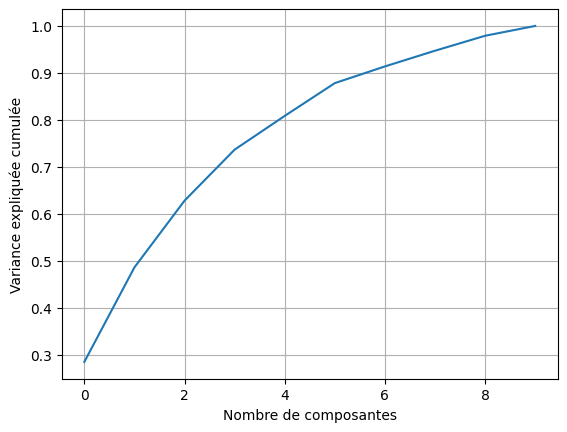

In [ ]:
#Choix du nombre de composantes
plt.plot(np.cumsum(explained_var))
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance expliquée cumulée")
plt.grid(True)
plt.show()

In [ ]:
# tableau de variance expliquée
explained_var = pca.explained_variance_ratio_

# Variance cumulée
cumulative_var = np.cumsum(explained_var)

# Trouver le nombre minimal de composantes dépassant 85%
seuil = 0.8
n_components_optimal = np.argmax(cumulative_var >= seuil) + 1

print("Nombre de composantes nécessaires :", n_components_optimal)
print("Variance expliquée cumulée :", cumulative_var[n_components_optimal - 1])


Nombre de composantes nécessaires : 5
Variance expliquée cumulée : 0.8086255816035807


J'ai donc 5 composants nécessaire qui comprend 80.86% de l'information contenue dans mes variables

## Cercle de corrélation

Voyons dans un premier temps, la contribution de chaque variables PC1 jusqu'a PC5

In [ ]:
import pandas as pd
import numpy as np

# Loadings : contributions des variables aux composantes
loadings = pca.components_.T   # shape (nb_variables, nb_composantes)

# Contributions pour PC1 à PC5
contrib_pc1 = (loadings[:, 0]**2) / np.sum(loadings[:, 0]**2)
contrib_pc2 = (loadings[:, 1]**2) / np.sum(loadings[:, 1]**2)
contrib_pc3 = (loadings[:, 2]**2) / np.sum(loadings[:, 2]**2)
contrib_pc4 = (loadings[:, 3]**2) / np.sum(loadings[:, 3]**2)
contrib_pc5 = (loadings[:, 4]**2) / np.sum(loadings[:, 4]**2)

# Tableau final
df_contrib = pd.DataFrame({
    'Variable': df_etude.columns,
    'Contribution_PC1 (%)': contrib_pc1 * 100,
    'Contribution_PC2 (%)': contrib_pc2 * 100,
    'Contribution_PC3 (%)': contrib_pc3 * 100,
    'Contribution_PC4 (%)': contrib_pc4 * 100,
    'Contribution_PC5 (%)': contrib_pc5 * 100
})

print(df_contrib)



                   Variable  Contribution_PC1 (%)  Contribution_PC2 (%)  \
0   Importations - Quantité              7.007335              5.221071   
1  Disponibilité intérieure              2.266992             36.581988   
2    Dependance Alimentaire              2.079021             10.005026   
3           Population_2017              0.260276             36.432646   
4            CroissanceDemo             11.893223              0.067463   
5         Indice Logistique             21.119277              1.507111   
6            Inflation 2017              9.230493              1.592691   
7      Croissance Inflation              2.197841              2.024688   
8          PIB par habitant             22.970641              0.354026   
9       Stabilité politique             20.974901              6.213290   

   Contribution_PC3 (%)  Contribution_PC4 (%)  Contribution_PC5 (%)  
0             16.445578             14.267087              6.593338  
1              1.011010           

On va pouvoir mettre un thème sur ces 5 tendances

*   PC1 : **Axe du niveau de développement économique et institutionnel**
Opposant les pays riches et stable avec une organisation logistique avec les pays moins développés stable et moins performant dans la logistiques.

*   PC2 : **Pression démographique et structure alimentaire**
Qui distingue les pays à forte population, avec une forte disponibilité alimentaire mais aussi une forte dépendance à la volaille


*   **PC3 : Risque de volatilité des prix**
Instabilité des prix avec une très forte croissance de l'inflation

*   **PC4 : Pression alimentaire structurelle**
Qui est mon axe de vulnérabilité alimentaire

*  **PC5 : Comportements atypiques** Pays à forte croissance et avec une forte dépendance alimentaire avec une inflation notable. Permets de détecter les pays hors normes


Confirmons ca par les cercles de corrélations







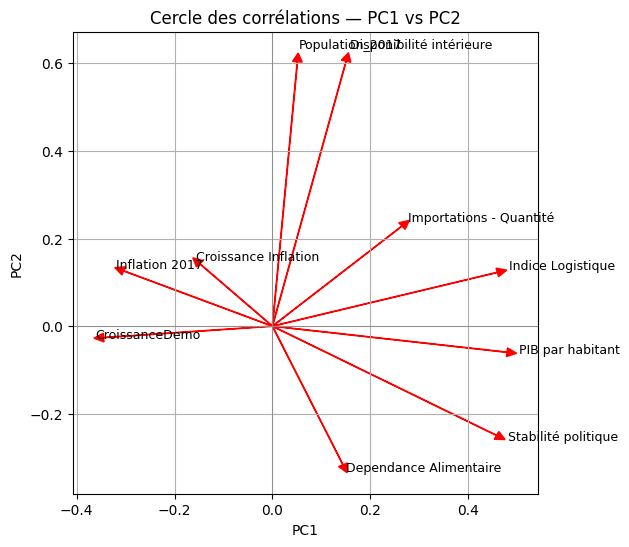

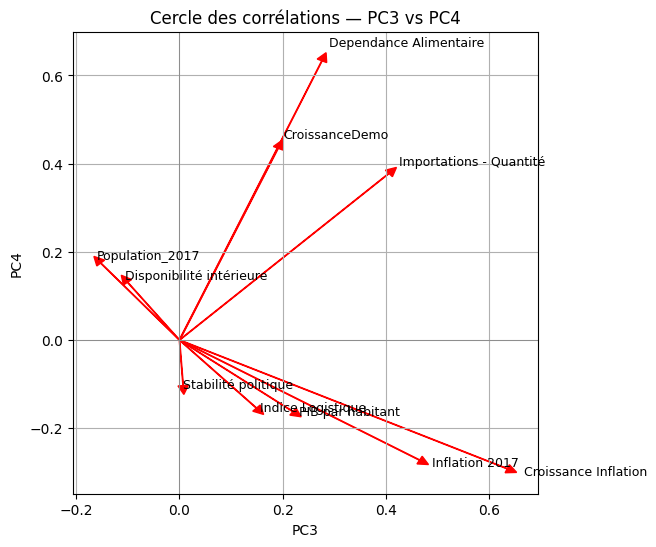

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

feature_names_for_pca = [
    "Importations - Quantité",
    "Disponibilité intérieure",
    "Dependance Alimentaire",
    "Population_2017",
    "CroissanceDemo",
    "Indice Logistique",
    "Inflation 2017",
    "Croissance Inflation",
    "PIB par habitant",
    "Stabilité politique"
]

# Loadings
loadings = pca.components_.T   # shape (nb_variables, nb_composantes)
variables = feature_names_for_pca

def plot_correlation_circle(pc_x, pc_y, loadings, variables):
    plt.figure(figsize=(6,6))

    # Loadings des deux composantes
    load = loadings[:, [pc_x, pc_y]]

    # Tracer les flèches
    for i, var in enumerate(variables):
        plt.arrow(0, 0,
                  load[i, 0],
                  load[i, 1],
                  head_width=0.02,
                  head_length=0.02,
                  fc='red', ec='red')
        plt.text(load[i, 0]*1.05,
                 load[i, 1]*1.05,
                 var,
                 fontsize=9)

    # Cercle unité
    circle = plt.Circle((0,0), 1, color='b', fill=False)
    plt.gca().add_artist(circle)

    # Axes
    plt.axhline(0, color='grey', linewidth=0.5)
    plt.axvline(0, color='grey', linewidth=0.5)

    plt.xlabel(f"PC{pc_x+1}")
    plt.ylabel(f"PC{pc_y+1}")
    plt.title(f"Cercle des corrélations — PC{pc_x+1} vs PC{pc_y+1}")
    plt.grid(True)
    plt.show()

# --- Tracer les cercles ---
plot_correlation_circle(0, 1, loadings, variables)  # PC1 vs PC2
plot_correlation_circle(2, 3, loadings, variables)  # PC3 vs PC4

Le plan PC1–PC2 distingue clairement les marchés “matures et stables” des marchés “massifs mais sous pression alimentaire”.
C’est la segmentation macro la plus structurante pour orienter les priorités pays.

Le plan PC3–PC4 met en lumière les pays cumulant inflation élevée, dépendance aux importations et croissance démographique rapide.
Ce sont les marchés les plus exposés aux chocs alimentaires et aux instabilités de prix.

Il serait interessent de voir l'intéraction entre PC1 qui représente le niveau de développement économique avec PC3 qui est la volatilité des prix

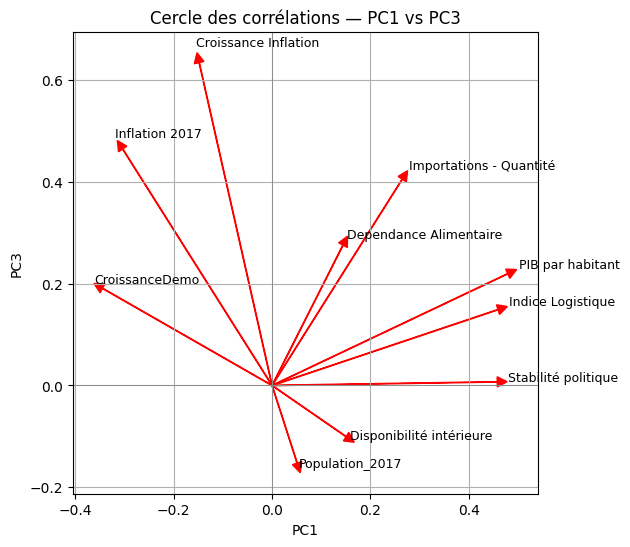

In [ ]:

feature_names_for_pca = [
    "Importations - Quantité",
    "Disponibilité intérieure",
    "Dependance Alimentaire",
    "Population_2017",
    "CroissanceDemo",
    "Indice Logistique",
    "Inflation 2017",
    "Croissance Inflation",
    "PIB par habitant",
    "Stabilité politique"
]

# Loadings
loadings = pca.components_.T
variables = feature_names_for_pca

def plot_correlation_circle(pc_x, pc_y, loadings, variables):
    plt.figure(figsize=(6,6))

    load = loadings[:, [pc_x, pc_y]]

    for i, var in enumerate(variables):
        plt.arrow(0, 0,
                  load[i, 0],
                  load[i, 1],
                  head_width=0.02,
                  head_length=0.02,
                  fc='red', ec='red')
        plt.text(load[i, 0]*1.05,
                 load[i, 1]*1.05,
                 var,
                 fontsize=9)

    circle = plt.Circle((0,0), 1, color='b', fill=False)
    plt.gca().add_artist(circle)

    plt.axhline(0, color='grey', linewidth=0.5)
    plt.axvline(0, color='grey', linewidth=0.5)

    plt.xlabel(f"PC{pc_x+1}")
    plt.ylabel(f"PC{pc_y+1}")
    plt.title(f"Cercle des corrélations — PC{pc_x+1} vs PC{pc_y+1}")
    plt.grid(True)
    plt.show()

# PC1 vs PC3
plot_correlation_circle(0, 2, loadings, variables)


Ce plan est idéal pour arbitrer les investissements : il oppose clairement les marchés attractifs et stables aux marchés risqués et volatils.

Pour affiner davantages mes corrélations, affichons une heatmap

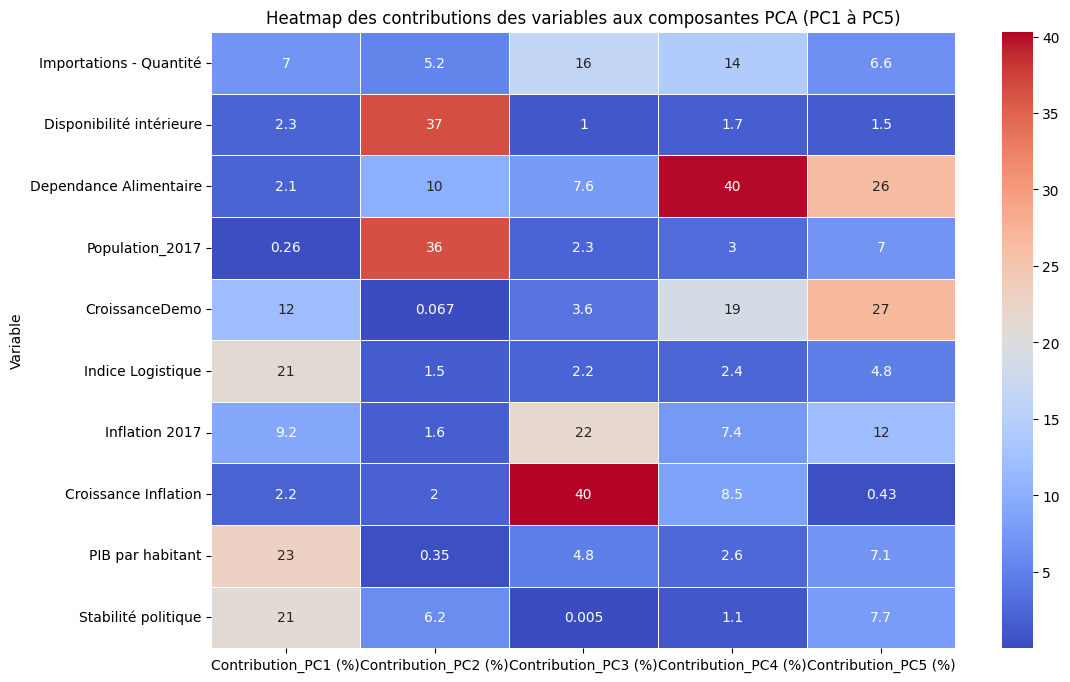

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# On enlève la colonne Variable pour ne garder que les contributions
df_heatmap = df_contrib.set_index("Variable")

plt.figure(figsize=(12, 8))
sns.heatmap(df_heatmap, annot=True, cmap="coolwarm", linewidths=.5)
plt.title("Heatmap des contributions des variables aux composantes PCA (PC1 à PC5)")
plt.show()



L’ACP segmente parfaitement les dimensions économiques, démographiques et alimentaires.
Les composantes sont indépendantes, ce qui garantit une analyse robuste et non redondante.

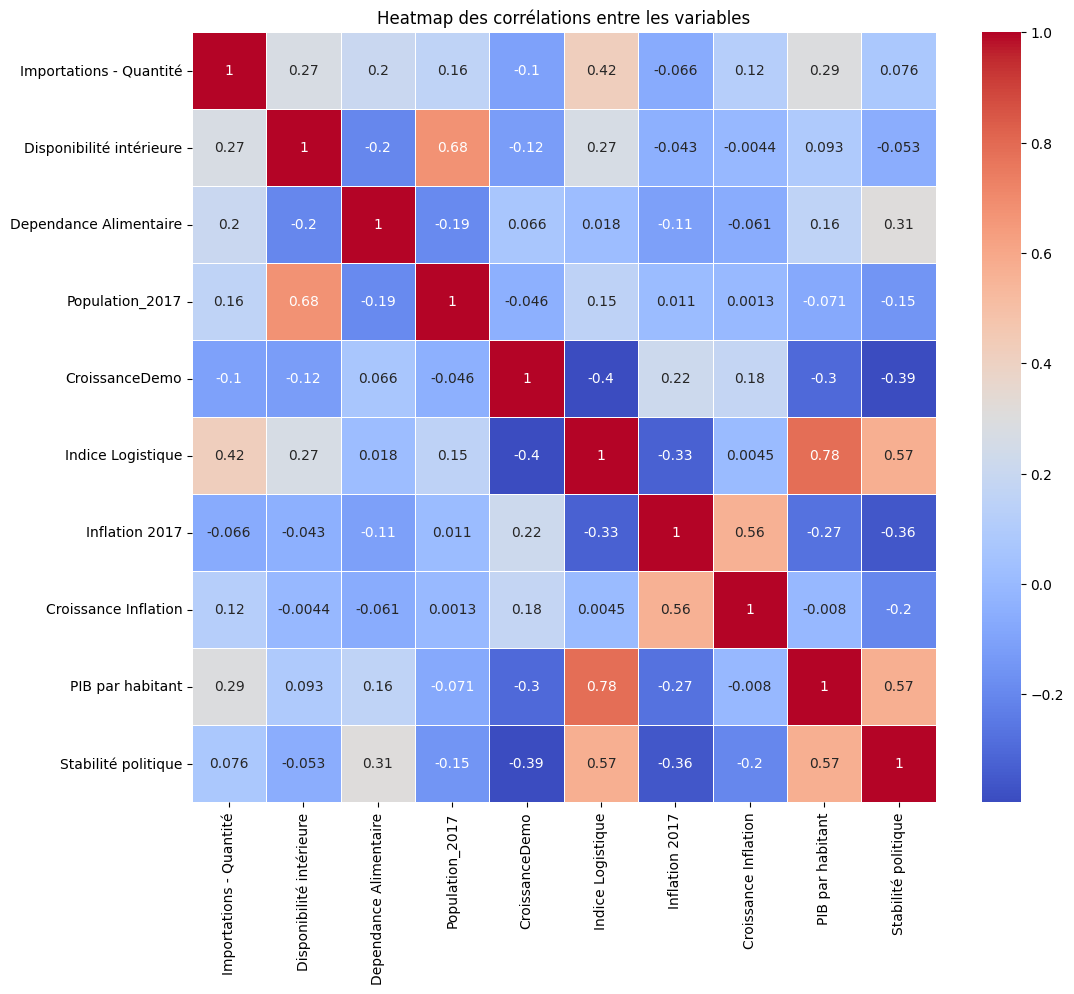

In [ ]:
# Matrice de corrélation des variables (sur les données standardisées)
corr_matrix = df_etude.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", linewidths=.5)
plt.title("Heatmap des corrélations entre les variables")
plt.show()

Les variables se regroupent naturellement en quatre familles cohérentes.
Cela valide la structure de l’ACP et confirme que chaque composante apporte une information unique.

## Projection des pays en fonction des composantes

### Projection des pays sur PC1-PC2 : Développement économique vs pression démographique

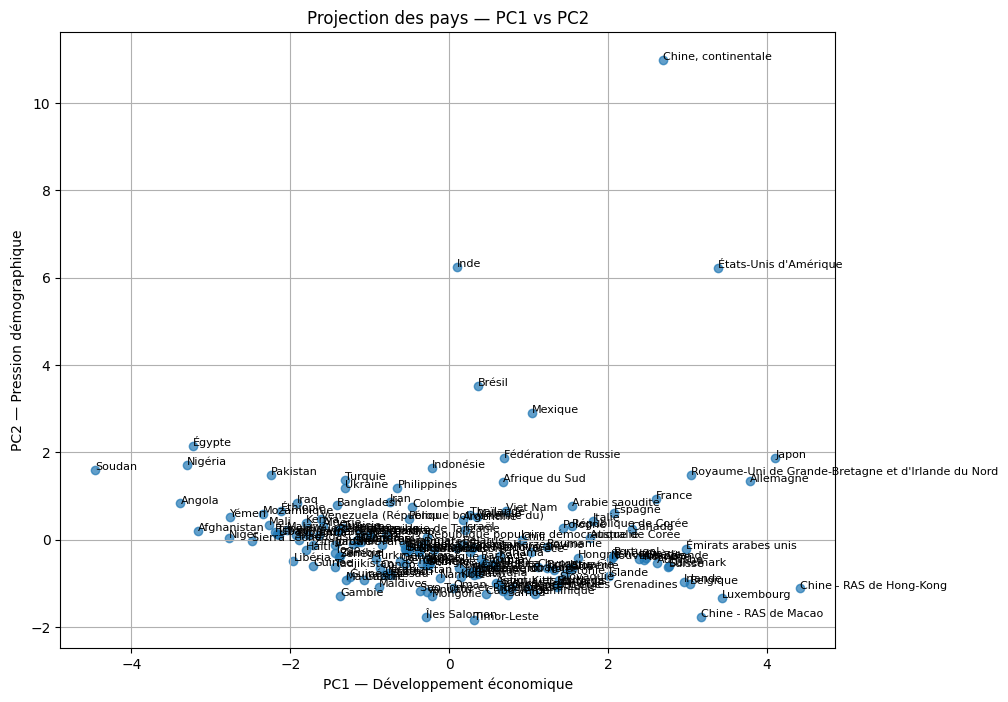

In [ ]:
# Scores des composantes (coordonnées des pays)
scores = pca.transform(df_etude_scaled_imputed)

plt.figure(figsize=(10, 8))

plt.scatter(scores[:, 0], scores[:, 1], alpha=0.7)

# Ajouter les noms des pays
for i, country_idx in enumerate(df_etude.index):
    plt.text(scores[i, 0], scores[i, 1], pays.iloc[country_idx], fontsize=8)

plt.xlabel("PC1 — Développement économique")
plt.ylabel("PC2 — Pression démographique")
plt.title("Projection des pays — PC1 vs PC2")
plt.grid(True)
plt.show()


Rien d'étonnant dans ces résultats, 3 pays sortent de la masse par leurs démographies, les pays les plus riches se trouvant à droite du graphique

### Projection PC1-PC3 : Développement économique vs volatilité des prix

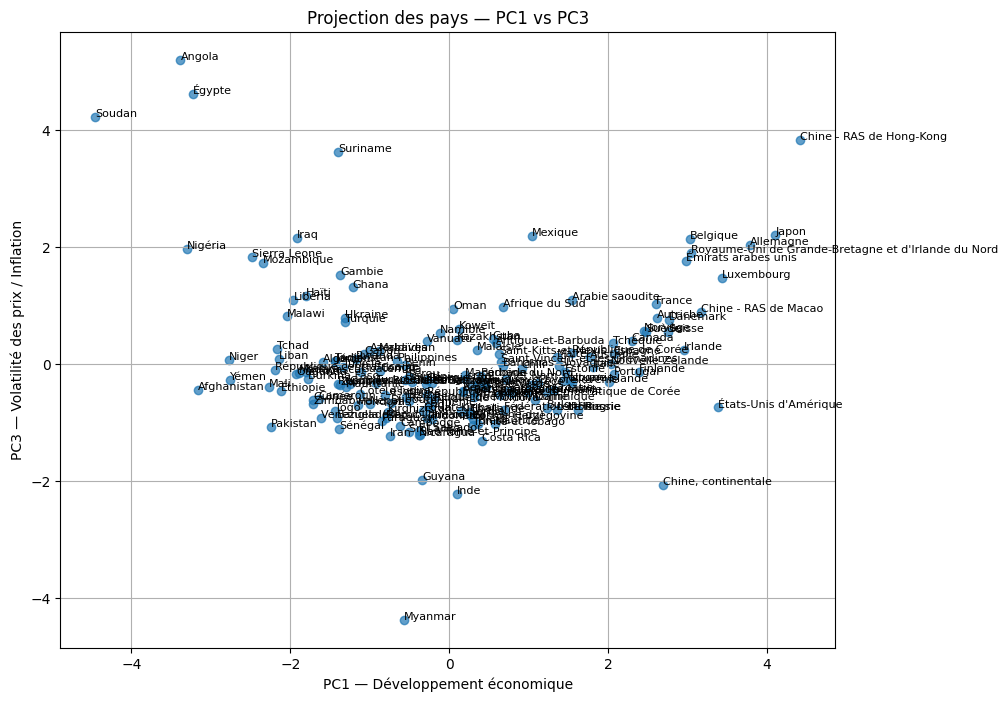

In [ ]:
plt.figure(figsize=(10, 8))

plt.scatter(scores[:, 0], scores[:, 2], alpha=0.7)

for i, country_name in enumerate(pays):
    plt.text(scores[i, 0], scores[i, 2], country_name, fontsize=8)

plt.xlabel("PC1 — Développement économique")
plt.ylabel("PC3 — Volatilité des prix / Inflation")
plt.title("Projection des pays — PC1 vs PC3")
plt.grid(True)
plt.show()

On remarque que les pays les plus développé ont une légère tendance à une inflation croissante

### Projection PC2- PC3 : Démographie vs volatilité

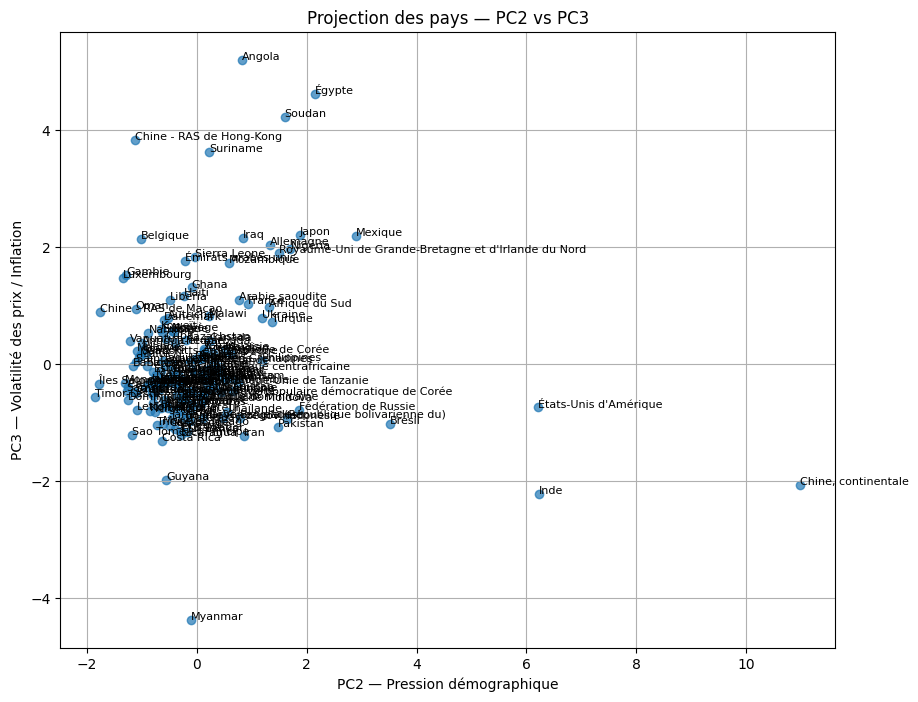

In [ ]:
plt.figure(figsize=(10, 8))

plt.scatter(scores[:, 1], scores[:, 2], alpha=0.7)

for i, country_name in enumerate(pays):
    plt.text(scores[i, 1], scores[i, 2], country_name, fontsize=8)

plt.xlabel("PC2 — Pression démographique")
plt.ylabel("PC3 — Volatilité des prix / Inflation")
plt.title("Projection des pays — PC2 vs PC3")
plt.grid(True)
plt.show()

###PC1 - PC4 : Developpement économique vs dépendance alimentaire

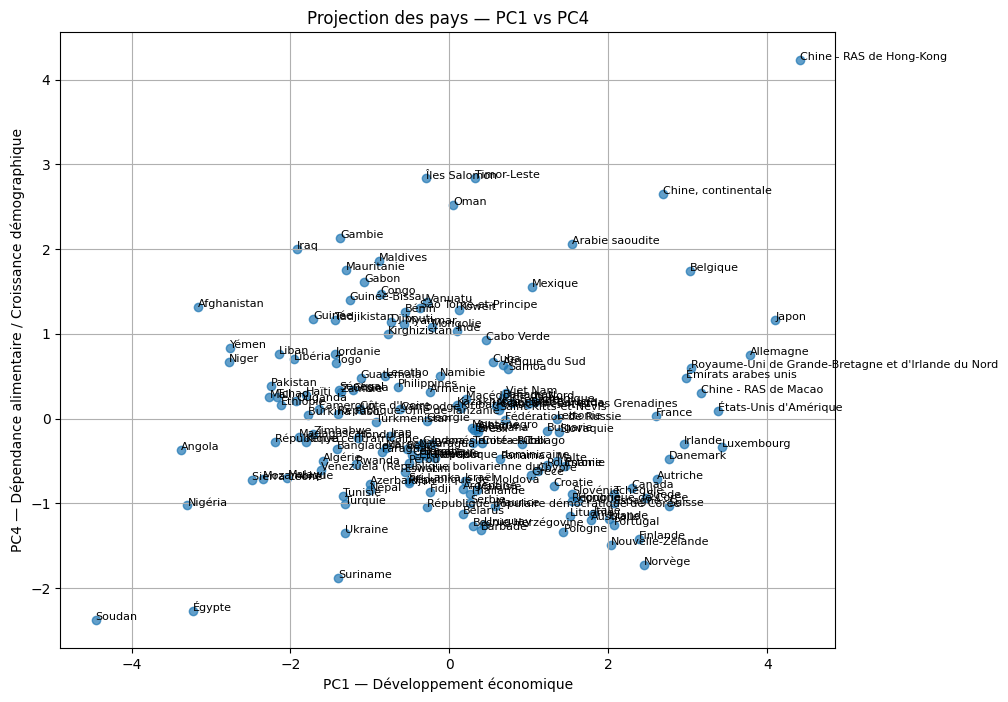

In [ ]:
plt.figure(figsize=(10, 8))

plt.scatter(scores[:, 0], scores[:, 3], alpha=0.7)

for i, country_name in enumerate(pays):
    plt.text(scores[i, 0], scores[i, 3], country_name, fontsize=8)

plt.xlabel("PC1 — Développement économique")
plt.ylabel("PC4 — Dépendance alimentaire / Croissance démographique")
plt.title("Projection des pays — PC1 vs PC4")
plt.grid(True)
plt.show()

Les pays riches ont une plus forte dépendance alimentaire, surement à cause des échanges commercieux entre les pays

## Classification acsendante hiérarchique (CAH)

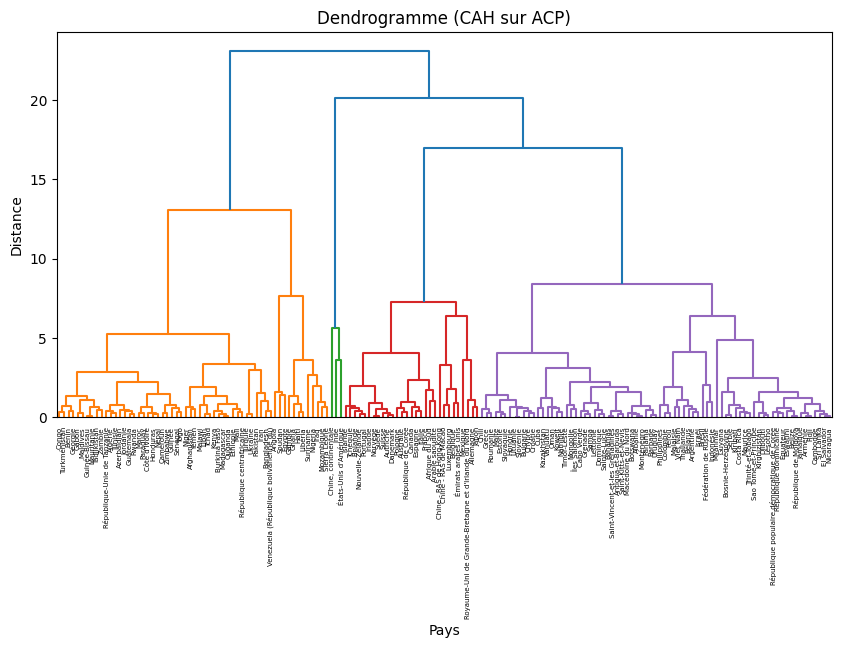

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# On garde par exemple les 3 premières composantes
df_etude_pca_k = df_etude_pca[:, :3]

Z = linkage(df_etude_pca_k, method='ward')  # Ward = minimise la variance intra-classe

plt.figure(figsize=(10, 5))
dendrogram(Z, labels=pays.tolist(), leaf_rotation=90)
plt.title("Dendrogramme (CAH sur ACP)")
plt.xlabel("Pays")
plt.ylabel("Distance")
plt.show()

Pour choisir le nombre de cluster, je vais utiliser la méthode de la silhouette

In [ ]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering

scores_silhouette = {}

for k in range(2, 10):
    model = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = model.fit_predict(df_etude_pca)
    score = silhouette_score(df_etude_pca, labels)
    scores_silhouette[k] = score

print(scores_silhouette)
print("Nombre optimal :", max(scores_silhouette, key=scores_silhouette.get))


{2: np.float64(0.30815223846914197), 3: np.float64(0.2805615648169718), 4: np.float64(0.2975023345093423), 5: np.float64(0.18117356550946917), 6: np.float64(0.1837947515440878), 7: np.float64(0.20140656913162538), 8: np.float64(0.18796896377621738), 9: np.float64(0.19153336475914598)}
Nombre optimal : 2


In [ ]:
n_clusters = 2
clusters_cah = fcluster(Z, n_clusters, criterion='maxclust')


In [ ]:
df_etude["Cluster_CAH"] = clusters_cah


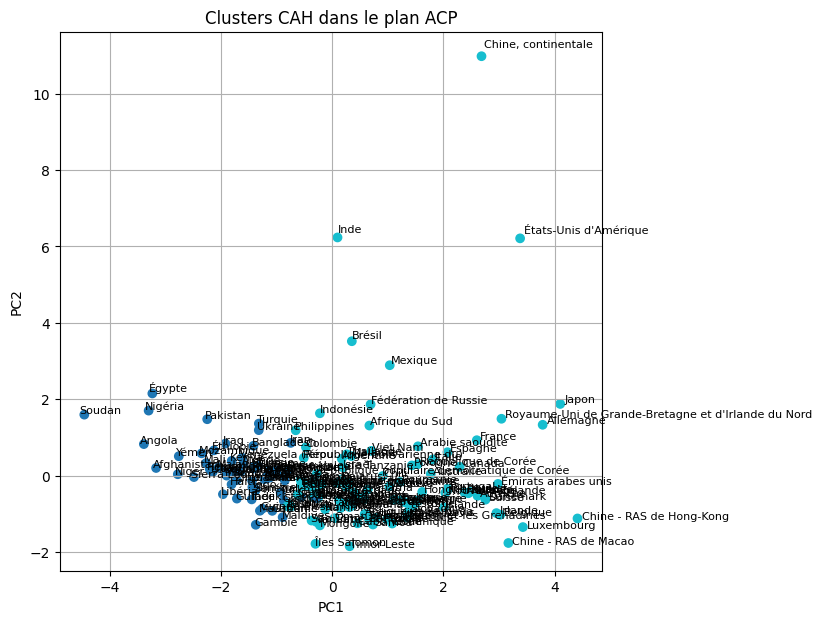

In [ ]:
#Visualisation des cluster pour PC1-PC2
plt.figure(figsize=(7,7))
scatter = plt.scatter(df_etude_pca[:,0], df_etude_pca[:,1], c=clusters_cah, cmap="tab10")
for i, name in enumerate(pays):
    plt.text(df_etude_pca[i,0]*1.02, df_etude_pca[i,1]*1.02, name, fontsize=8)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clusters CAH dans le plan ACP")
plt.grid(True)
plt.show()

# K-mean

## K-means sur l'ACP

In [ ]:
#Déterminer le nombre de cluster via la méthode du coude
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

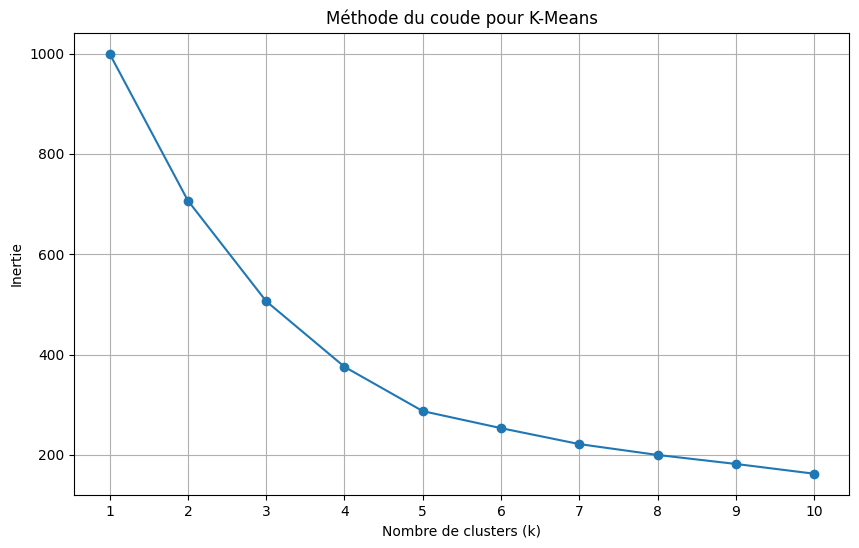

In [ ]:
inertia = []
k_range = range(1, 11)  # Tester de 1 à 10 clusters

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10) # n_init pour éviter les avertissements
    kmeans.fit(df_etude_pca_k)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(k_range, inertia, marker='o')
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Inertie')
plt.title('Méthode du coude pour K-Means')
plt.xticks(k_range)
plt.grid(True)
plt.show()

Pour interpréter la méthode du coude, il faut rechercher le point sur le graphique où la diminution de l'inertie commence à ralentir considérablement, formant un « coude ». Ce point représente un bon compromis entre la réduction de la variance intra-cluster et le nombre de clusters, suggérant un nombre optimal de clusters. Avec l'observation graphique, nous arrivons à 3-4 clusters. Nous allons maintenant calculer le score de silhouette pour K-Means afin de confirmer ce choix.

In [ ]:
from sklearn.metrics import silhouette_score

scores_silhouette_kmeans = {}

for k in k_range:
    if k == 1:
        scores_silhouette_kmeans[k] = -1
        continue
    kmeans_model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_kmeans = kmeans_model.fit_predict(df_etude_pca_k)
    score = silhouette_score(df_etude_pca_k, labels_kmeans)
    scores_silhouette_kmeans[k] = score

print("Scores de silhouette pour K-Means :", scores_silhouette_kmeans)
optimal_k_silhouette_kmeans = max(scores_silhouette_kmeans, key=scores_silhouette_kmeans.get)
print("Nombre optimal de clusters (selon le score de silhouette) :", optimal_k_silhouette_kmeans)

Scores de silhouette pour K-Means : {1: -1, 2: np.float64(0.33050718038928745), 3: np.float64(0.3549144616648197), 4: np.float64(0.3430110036549178), 5: np.float64(0.3323018310653954), 6: np.float64(0.29787725201966386), 7: np.float64(0.29308136631700943), 8: np.float64(0.3181005505107968), 9: np.float64(0.30436253851841855), 10: np.float64(0.28865249173923624)}
Nombre optimal de clusters (selon le score de silhouette) : 3


J'ai une différence entre mon CAH et mon K-Mean, ce qui est normale. Le CAH construit les clusters en fusionnant progressivement selon une logique hiérarchique pendant que le K-Mean cherche directement la meilleur partition en minimisant la variance interne. Le K-Mean étant plus sensible aux centroides pendant que le CAH lui est sensible aux distances relatives entres pays, je choisi le nombre de cluster du K-Means soit 3

In [ ]:
from sklearn.cluster import KMeans

n_clusters_kmeans = 3
kmeans = KMeans(n_clusters=n_clusters_kmeans, random_state=42, n_init=10)
clusters_km = kmeans.fit_predict(df_etude_pca_k)

df_etude["Cluster_KMeans"] = clusters_km

Maintenant que j'ai les cluster (CAH et K-means), je vais décrire les 3 clusters

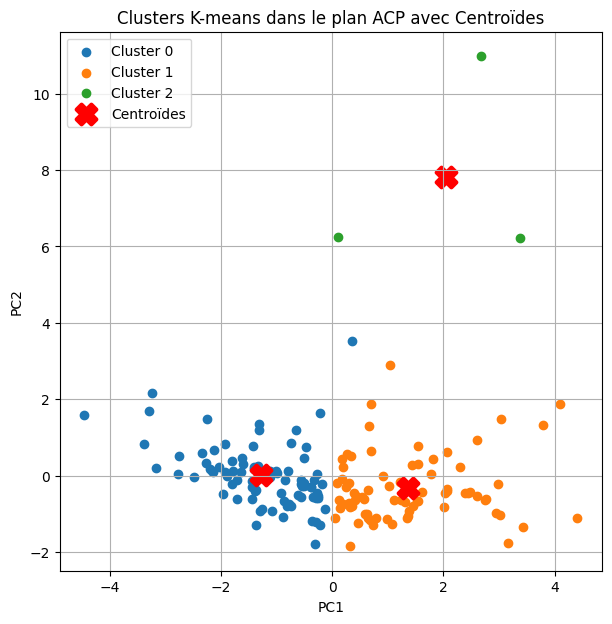

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(7,7))

unique_clusters = np.unique(clusters_km)

for cluster_label in unique_clusters:
    cluster_points = df_etude_pca[clusters_km == cluster_label]
    plt.scatter(cluster_points[:, 0], cluster_points[:, 1],
                label=f'Cluster {cluster_label}')

# Centroïdes en rouge pour les distinguer
centroids = kmeans.cluster_centers_
plt.scatter(centroids[:, 0], centroids[:, 1],
            marker='X', s=200, linewidths=3,
            color='red', label='Centroïdes')

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clusters K-means dans le plan ACP avec Centroïdes")
plt.grid(True)
plt.legend()
plt.show()


In [ ]:
df_etude.groupby("Cluster_KMeans").mean()


,Importations - Quantité,Disponibilité intérieure,Dependance Alimentaire,Population_2017,CroissanceDemo,Indice Logistique,Inflation 2017,Croissance Inflation,PIB par habitant,Stabilité politique,Cluster_CAH
Cluster_KMeans,,,,,,,,,,,
0,33.883721,401.906977,36.588161,3.152074e+07,10.389860,2.519600,6.226928,-0.973747,8293.023529,-0.649651,1.325581
1,143.907895,534.565789,56.196081,1.949815e+07,3.504185,3.315968,1.971332,-2.153335,39668.746667,0.554079,2.000000
2,191.666667,13362.666667,1.054077,1.028261e+09,3.978135,3.560000,2.350473,-2.330301,27436.666667,-0.253333,2.000000


Le cluster 1 comprend les pays les plus avantageux pour cette étude, soit les pays riche avec un fort développement economique et une grande pression demographique

# Visualisation des Cluster

In [ ]:
#Liste des pays du cluster 1
pays_cluster1 = df_etude[df_etude["Cluster_KMeans"] == 1].index
print(pays[pays_cluster1])

1           Afrique du Sud
2                  Albanie
4                Allemagne
6       Antigua-et-Barbuda
7          Arabie saoudite
              ...         
145            Timor-Leste
147      Trinité-et-Tobago
152                Uruguay
155               Viet Nam
160    Émirats arabes unis
Name: Pays, Length: 76, dtype: object


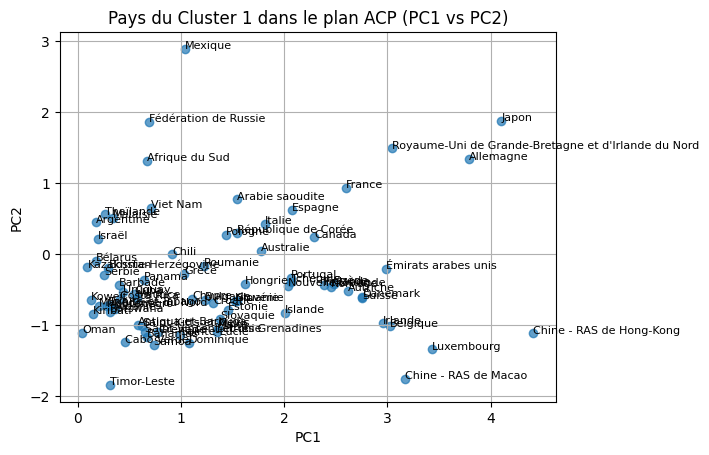

In [ ]:
cluster_1_indices = df_etude[df_etude['Cluster_KMeans'] == 1].index

# Filtrer les scores PCA pour le cluster 1
pca_cluster_1 = df_etude_pca[cluster_1_indices, :]
pays_cluster_1_names = pays[cluster_1_indices]

plt.scatter(pca_cluster_1[:, 0], pca_cluster_1[:, 1], alpha=0.7)

for i, country_name in enumerate(pays_cluster_1_names):
    plt.text(pca_cluster_1[i, 0], pca_cluster_1[i, 1], country_name, fontsize=8)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Pays du Cluster 1 dans le plan ACP (PC1 vs PC2)")
plt.grid(True)
plt.show()

In [ ]:
#Construire un score de recommandation par pays
from sklearn.preprocessing import MinMaxScaler

vars_score = [
    "Importations - Quantité",
    "Dependance Alimentaire",
    "Population_2017",
    "CroissanceDemo",
    "Indice Logistique",
    "Inflation 2017",
    "Croissance Inflation",
    "PIB par habitant",
    "Stabilité politique"
]

df_score = df_etude[vars_score].copy()

scaler = MinMaxScaler()
df_score_scaled = pd.DataFrame(
    scaler.fit_transform(df_score),
    columns=vars_score,
    index=df_etude.index
)


In [ ]:
#Gestion des variables négatives
df_score_scaled["Inflation 2017_inv"] = 1 - df_score_scaled["Inflation 2017"]
df_score_scaled["Croissance Inflation_inv"] = 1 - df_score_scaled["Croissance Inflation"]


In [ ]:
#Définition du score global
w = {
    "Importations - Quantité": 0.15,
    "Dependance Alimentaire": 0.15,
    "Population_2017": 0.10,
    "CroissanceDemo": 0.10,
    "Indice Logistique": 0.15,
    "Inflation 2017_inv": 0.10,
    "Croissance Inflation_inv": 0.05,
    "PIB par habitant": 0.10,
    "Stabilité politique": 0.10
}

df_score_scaled["Score_reco"] = (
    df_score_scaled["Importations - Quantité"] * w["Importations - Quantité"] +
    df_score_scaled["Dependance Alimentaire"] * w["Dependance Alimentaire"] +
    df_score_scaled["Population_2017"] * w["Population_2017"] +
    df_score_scaled["CroissanceDemo"] * w["CroissanceDemo"] +
    df_score_scaled["Indice Logistique"] * w["Indice Logistique"] +
    df_score_scaled["Inflation 2017_inv"] * w["Inflation 2017_inv"] +
    df_score_scaled["Croissance Inflation_inv"] * w["Croissance Inflation_inv"] +
    df_score_scaled["PIB par habitant"] * w["PIB par habitant"] +
    df_score_scaled["Stabilité politique"] * w["Stabilité politique"]
)


In [ ]:
df_etude["Score_reco"] = df_score_scaled["Score_reco"]


In [ ]:
clusters_prioritaires = [1]
df_cibles = df_etude[df_etude["Cluster_KMeans"].isin(clusters_prioritaires)].copy()

# Rajouter les pays pour le résultat
df_cibles["Pays"] = pays[df_cibles.index]

df_cibles = df_cibles.sort_values("Score_reco", ascending=False)

df_cibles[["Pays", "Cluster_KMeans", "Score_reco"]].head(20)

,Pays,Cluster_KMeans,Score_reco
30,Chine - RAS de Hong-Kong,1,0.678952
73,Japon,1,0.569591
4,Allemagne,1,0.553945
16,Belgique,1,0.541469
118,Royaume-Uni de Grande-Bretagne et d'Irlande du...,1,0.510755
85,Luxembourg,1,0.509851
108,Oman,1,0.477270
7,Arabie saoudite,1,0.463479
49,France,1,0.460410
40,Danemark,1,0.459102


In [ ]:
#Top 5 des pays recommandé

clusters_prioritaires = [1]

# Filtrer les pays appartenant aux clusters prioritaires
df_cibles = df_etude[df_etude["Cluster_KMeans"].isin(clusters_prioritaires)].copy()

# Ajouter les pays
df_cibles["Pays"] = pays[df_cibles.index]

# Trier par score décroissant
df_top5 = df_cibles.sort_values("Score_reco", ascending=False).head(5)

# Afficher le Top 5
df_top5[["Pays", "Cluster_KMeans", "Score_reco"]]

,Pays,Cluster_KMeans,Score_reco
30,Chine - RAS de Hong-Kong,1,0.678952
73,Japon,1,0.569591
4,Allemagne,1,0.553945
16,Belgique,1,0.541469
118,Royaume-Uni de Grande-Bretagne et d'Irlande du...,1,0.510755


Nous avons notre top 5. Dans celui ci, nous allons éviter la Chine et le Japon qui sont loin de la France, ainsi que le Royaume-Uni qui a quitté l'EU recemment.

Les Pays les plus avantageux pour s'étendre sont donc l'Allemagne et la Belgique

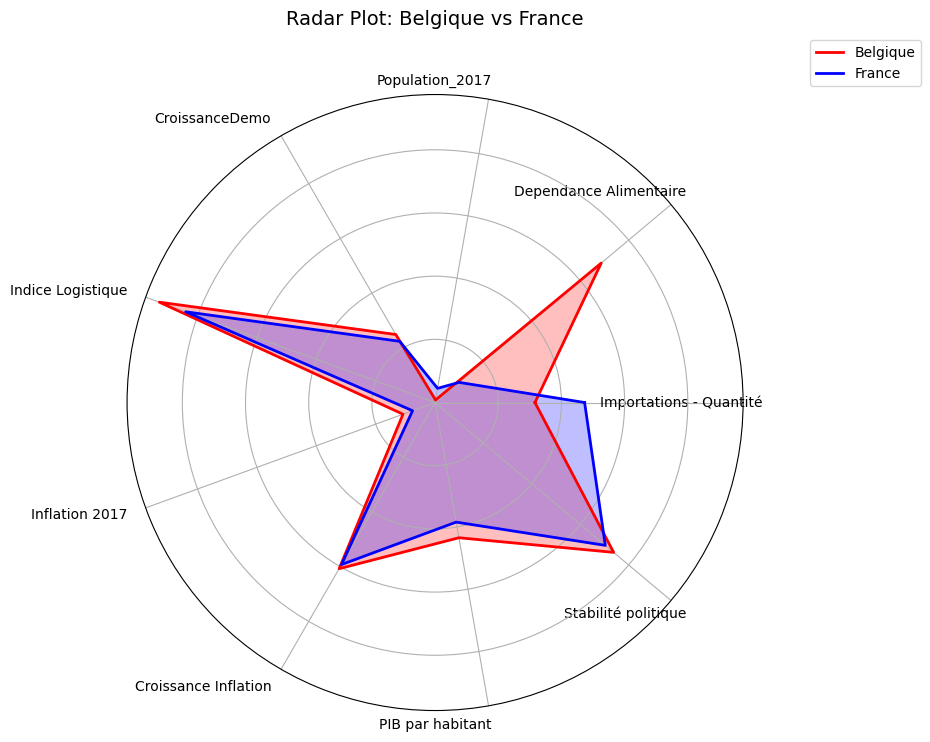

In [ ]:
# Recupérer la Belgique et la France
index_belgique = pays[pays == 'Belgique'].index[0]
index_france = pays[pays == 'France'].index[0]

# Récupération de mes variable
variables_for_radar = [
    "Importations - Quantité",
    "Dependance Alimentaire",
    "Population_2017",
    "CroissanceDemo",
    "Indice Logistique",
    "Inflation 2017",
    "Croissance Inflation",
    "PIB par habitant",
    "Stabilité politique"
]

# Normalisation des valeurs
values_belgique = df_score_scaled.loc[index_belgique, variables_for_radar].values
values_france = df_score_scaled.loc[index_france, variables_for_radar].values

num_vars = len(variables_for_radar)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

values_belgique = np.concatenate((values_belgique, [values_belgique[0]]))
values_france = np.concatenate((values_france, [values_france[0]]))
angles = np.concatenate((angles, [angles[0]]))

# Création du radar
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

ax.plot(angles, values_belgique, color='red', linewidth=2, label='Belgique')
ax.fill(angles, values_belgique, color='red', alpha=0.25)

ax.plot(angles, values_france, color='blue', linewidth=2, label='France')
ax.fill(angles, values_france, color='blue', alpha=0.25)

ax.set_yticklabels([])
ax.set_xticks(angles[:-1])
ax.set_xticklabels(variables_for_radar, fontsize=10, rotation=45, ha='right')

plt.title('Radar Plot: Belgique vs France', size=14, color='black', y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

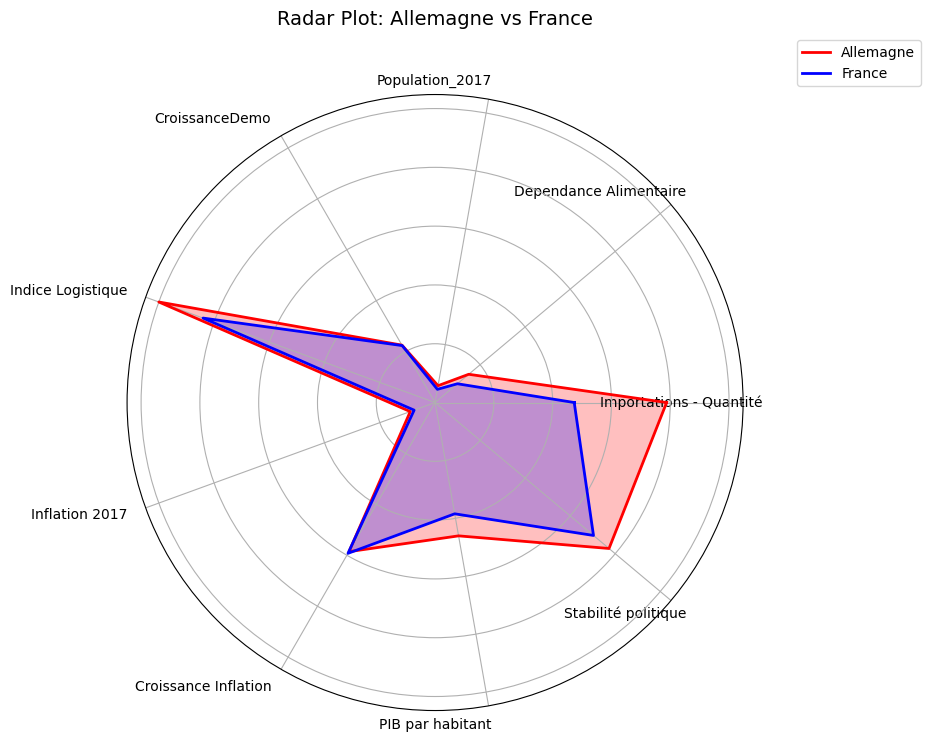

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Recupération de l'Allemagne et de la France
index_allemagne = pays[pays == 'Allemagne'].index[0]
index_france = pays[pays == 'France'].index[0]

# Recupération de mes variables
variables_for_radar = [
    "Importations - Quantité",
    "Dependance Alimentaire",
    "Population_2017",
    "CroissanceDemo",
    "Indice Logistique",
    "Inflation 2017",
    "Croissance Inflation",
    "PIB par habitant",
    "Stabilité politique"
]

# Normalisation des valeurs
values_allemagne = df_score_scaled.loc[index_allemagne, variables_for_radar].values
values_france = df_score_scaled.loc[index_france, variables_for_radar].values

num_vars = len(variables_for_radar)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

values_allemagne = np.concatenate((values_allemagne, [values_allemagne[0]]))
values_france = np.concatenate((values_france, [values_france[0]]))
angles = np.concatenate((angles, [angles[0]]))

# Création du radar
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

ax.plot(angles, values_allemagne, color='red', linewidth=2, label='Allemagne')
ax.fill(angles, values_allemagne, color='red', alpha=0.25)

ax.plot(angles, values_france, color='blue', linewidth=2, label='France')
ax.fill(angles, values_france, color='blue', alpha=0.25)

ax.set_yticklabels([])
ax.set_xticks(angles[:-1])
ax.set_xticklabels(variables_for_radar, fontsize=10, rotation=45, ha='right')

plt.title('Radar Plot: Allemagne vs France', size=14, color='black', y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()